In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# pandas output display setup
pd.options.display.float_format = '{:,.2f}'.format

In [2]:
sales = pd.read_csv('C:/piton shhss/time series statistik/data_penjualan.csv', sep=';')

In [3]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1076 entries, 0 to 1075
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Tanggal       1076 non-null   object
 1   Jenis Produk  1076 non-null   object
 2   Jumlah Order  1076 non-null   int64 
 3   Harga         1076 non-null   int64 
 4   Total         1076 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 42.2+ KB


In [4]:
# Ensure the column is of string type before using .str methods
sales['Jumlah Order'] = sales['Jumlah Order'].astype(str)

# Replace ',00' and '.' with appropriate values
sales['Jumlah Order'] = sales['Jumlah Order'].str.replace(',00', '', regex=False)
sales['Jumlah Order'] = sales['Jumlah Order'].str.replace('.', '', regex=False)

# Convert the column back to float
sales['Jumlah Order'] = sales['Jumlah Order'].astype(float)

In [5]:
print(sales['Jumlah Order'].dtype)
print(sales['Jumlah Order'].head())

float64
0   1,000.00
1   1,000.00
2   5,000.00
3   1,000.00
4   1,000.00
Name: Jumlah Order, dtype: float64


In [6]:
# Ensure the column is of string type before using .str methods
sales['Total'] = sales['Total'].astype(str)

# Replace 'Rp', '.', and ',00' with appropriate values
sales['Total'] = sales['Total'].str.replace('Rp', '', regex=False)
sales['Total'] = sales['Total'].str.replace('.', '', regex=False)
sales['Total'] = sales['Total'].str.replace(',00', '', regex=False)

# Convert the column back to float
sales['Total'] = sales['Total'].astype(float)

In [7]:
print(sales['Total'].dtype)
print(sales['Total'].head())

float64
0   1,800,000.00
1   1,900,000.00
2   3,750,000.00
3   1,200,000.00
4   1,550,000.00
Name: Total, dtype: float64


In [8]:
sales.dtypes

Tanggal          object
Jenis Produk     object
Jumlah Order    float64
Harga             int64
Total           float64
dtype: object

In [9]:
sales.head()

,Tanggal,Jenis Produk,Jumlah Order,Harga,Total
0,05/08/2022,Foodpak260,"1,000.00",1800,"1,800,000.00"
1,05/08/2022,FoodpakMatte245,"1,000.00",1900,"1,900,000.00"
2,05/08/2022,CraftLaminasi290,"5,000.00",750,"3,750,000.00"
3,05/08/2022,CraftLaminasi290,"1,000.00",1200,"1,200,000.00"
4,07/08/2022,Dupleks310,"1,000.00",1550,"1,550,000.00"


In [10]:
sales['Tanggal'] = pd.to_datetime(sales['Tanggal'], format="mixed", dayfirst=True)
sales.head()

,Tanggal,Jenis Produk,Jumlah Order,Harga,Total
0,2022-08-05,Foodpak260,"1,000.00",1800,"1,800,000.00"
1,2022-08-05,FoodpakMatte245,"1,000.00",1900,"1,900,000.00"
2,2022-08-05,CraftLaminasi290,"5,000.00",750,"3,750,000.00"
3,2022-08-05,CraftLaminasi290,"1,000.00",1200,"1,200,000.00"
4,2022-08-07,Dupleks310,"1,000.00",1550,"1,550,000.00"


In [11]:
sales = sales.sort_values(by = 'Tanggal')
sales

,Tanggal,Jenis Produk,Jumlah Order,Harga,Total
0,2022-08-05,Foodpak260,"1,000.00",1800,"1,800,000.00"
1,2022-08-05,FoodpakMatte245,"1,000.00",1900,"1,900,000.00"
2,2022-08-05,CraftLaminasi290,"5,000.00",750,"3,750,000.00"
3,2022-08-05,CraftLaminasi290,"1,000.00",1200,"1,200,000.00"
4,2022-08-07,Dupleks310,"1,000.00",1550,"1,550,000.00"
...,...,...,...,...,...
1067,2023-11-14,FoodpakGlossy,500.00,2650,"1,325,000.00"
1073,2023-11-15,CraftLaminasi290,"1,500.00",875,"1,312,500.00"
1074,2023-11-15,FoodpakMatte,"1,000.00",2200,"2,200,000.00"
1072,2023-11-15,CraftLaminasi290,"2,000.00",800,"1,600,000.00"


In [12]:
sales.head()

,Tanggal,Jenis Produk,Jumlah Order,Harga,Total
0,2022-08-05,Foodpak260,"1,000.00",1800,"1,800,000.00"
1,2022-08-05,FoodpakMatte245,"1,000.00",1900,"1,900,000.00"
2,2022-08-05,CraftLaminasi290,"5,000.00",750,"3,750,000.00"
3,2022-08-05,CraftLaminasi290,"1,000.00",1200,"1,200,000.00"
4,2022-08-07,Dupleks310,"1,000.00",1550,"1,550,000.00"


In [13]:
# Menambahkan kolom no berisi nomor baris
sales['No'] = sales.index

# Membuat pivot table dengan kolom no sebagai indeks tambahan
daily_sales = sales.pivot_table(index=['No','Tanggal', 'Jenis Produk', 'Harga'], values=['Jumlah Order', 'Total'], aggfunc='sum').reset_index()

# Menampilkan lima baris pertama hasilnya
daily_sales.head()

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
0,0,2022-08-05,Foodpak260,1800,"1,000.00","1,800,000.00"
1,1,2022-08-05,FoodpakMatte245,1900,"1,000.00","1,900,000.00"
2,2,2022-08-05,CraftLaminasi290,750,"5,000.00","3,750,000.00"
3,3,2022-08-05,CraftLaminasi290,1200,"1,000.00","1,200,000.00"
4,4,2022-08-07,Dupleks310,1550,"1,000.00","1,550,000.00"


In [14]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[daily_sales['Jenis Produk'].str.contains('dupleks270', case=False, regex=False)]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
30,30,2022-08-15,Dupleks270,1900,"1,000.00","1,900,000.00"
35,35,2022-08-18,Dupleks270,2200,500.00,"1,100,000.00"
51,51,2022-08-30,Dupleks270Eplex,1300,"3,000.00","3,900,000.00"
83,83,2022-09-14,Dupleks270,1800,"1,000.00","1,800,000.00"
151,151,2022-10-24,Dupleks270Laminating,2000,"1,000.00","2,000,000.00"
203,203,2022-11-22,Dupleks270,1800,"1,000.00","1,800,000.00"
252,252,2022-12-07,Dupleks270,1500,"1,000.00","1,500,000.00"
271,271,2022-12-14,Dupleks270,2000,"1,000.00","2,000,000.00"
275,275,2022-12-15,Dupleks270Eplex,1300,"3,000.00","3,900,000.00"
344,344,2023-01-06,Dupleks270,1500,"1,000.00","1,500,000.00"


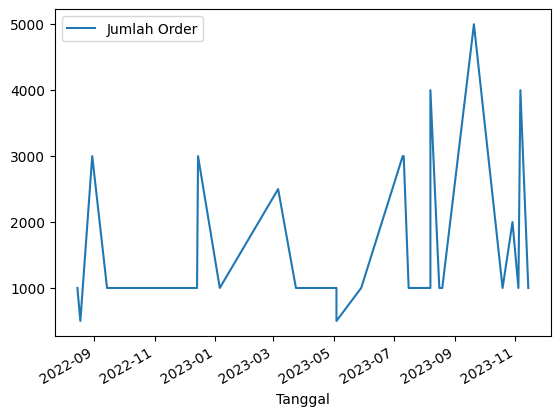

In [15]:
dupleks_270 = daily_sales[daily_sales['Jenis Produk'].str.contains('Dupleks270', case=False, regex=False)]

# Ubah tipe data kolom Jumlah Order menjadi numerik
dupleks_270['Jumlah Order'] = pd.to_numeric(dupleks_270['Jumlah Order'], errors='coerce')

# Gunakan metode .loc untuk mengubah data secara langsung
dupleks_270.loc[dupleks_270['Jumlah Order'].isna(), 'Jumlah Order'] = 5

# Buat plot garis untuk kolom Jumlah Order
dupleks_270.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [16]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[(daily_sales['Jenis Produk'].str.contains("dupleks310", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
4,4,2022-08-07,Dupleks310,1550,"1,000.00","1,550,000.00"
5,5,2022-08-08,Dupleks310,1900,500.00,"950,000.00"
11,11,2022-08-10,Dupleks310,1600,500.00,"800,000.00"
16,16,2022-08-11,Dupleks310,1300,"2,000.00","2,600,000.00"
28,28,2022-08-15,Dupleks310,1600,"2,000.00","3,200,000.00"
...,...,...,...,...,...,...
1037,1037,2023-11-03,Dupleks310,1600,"2,000.00","3,200,000.00"
1043,1043,2023-11-07,Dupleks310Eplex,1800,"2,000.00","3,600,000.00"
1054,1054,2023-11-09,Dupleks310,1500,"1,000.00","1,500,000.00"
1057,1057,2023-11-11,Dupleks310,1900,"1,000.00","1,900,000.00"


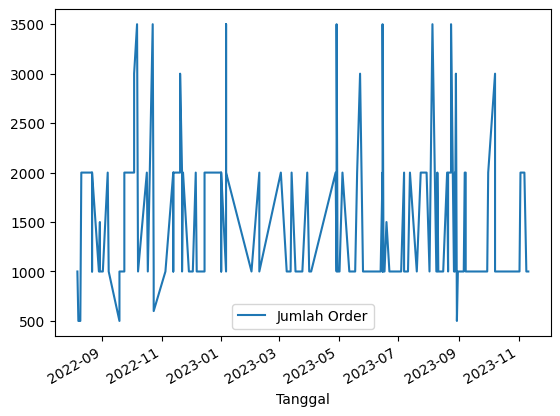

In [17]:
#Grafik Time Series
dupleks_310 = daily_sales[(daily_sales['Jenis Produk'].str.contains("dupleks310", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
dupleks_310['Jumlah Order'] = pd.to_numeric(dupleks_310['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
dupleks_310.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [18]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[(daily_sales['Jenis Produk'].str.contains("dupleks350", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
9,9,2022-08-09,Dupleks350,1800,500.00,"900,000.00"
10,10,2022-08-09,Dupleks350,1800,500.00,"900,000.00"
14,14,2022-08-11,Dupleks350,1800,500.00,"900,000.00"
15,15,2022-08-11,Dupleks350,1800,500.00,"900,000.00"
19,19,2022-08-12,Dupleks350,2200,"1,000.00","2,200,000.00"
...,...,...,...,...,...,...
1059,1059,2023-11-11,Dupleks350,1700,"1,000.00","1,700,000.00"
1060,1060,2023-11-11,Dupleks350,2000,"3,500.00","7,000,000.00"
1061,1061,2023-11-11,Dupleks350,1900,"3,500.00","6,650,000.00"
1062,1062,2023-11-11,Dupleks350,1600,"3,000.00","4,800,000.00"


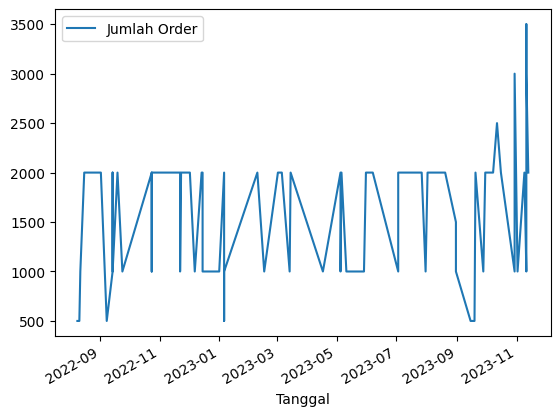

In [19]:
 
#Grafik Time Series
dupleks_350 = daily_sales[(daily_sales['Jenis Produk'].str.contains("dupleks350", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
dupleks_350['Jumlah Order'] = pd.to_numeric(dupleks_350['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
dupleks_350.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [20]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory230", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
23,23,2022-08-15,Ivory230+LaminasiDoff,1100,"1,500.00","1,650,000.00"
26,26,2022-08-15,Ivory230,950,"3,000.00","2,850,000.00"
47,47,2022-08-29,Ivory230,1450,"2,000.00","2,900,000.00"
59,59,2022-09-02,Ivory230,945,"2,000.00","1,890,000.00"
64,64,2022-09-05,Ivory230,1200,"1,000.00","1,200,000.00"
...,...,...,...,...,...,...
1050,1050,2023-11-08,Ivory230,1100,"3,500.00","3,850,000.00"
1055,1055,2023-11-10,Ivory230,1400,"1,000.00","1,400,000.00"
1056,1056,2023-11-10,Ivory230,1600,"1,000.00","1,600,000.00"
1070,1070,2023-11-14,Ivory230,1300,"1,000.00","1,300,000.00"


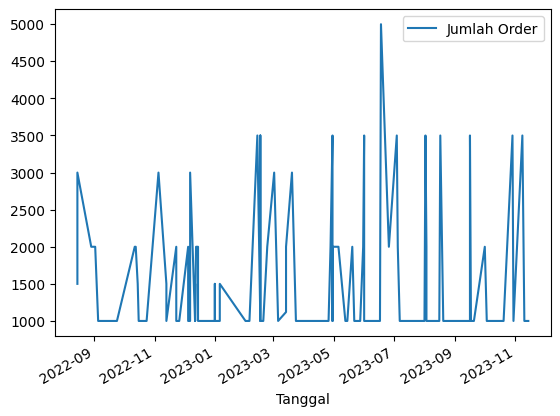

In [21]:
#Grafik Time Series
ivory_230 = daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory230", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
ivory_230['Jumlah Order'] = pd.to_numeric(ivory_230['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
ivory_230.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [22]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory250", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
53,53,2022-08-31,Ivory250,1600,"1,000.00","1,600,000.00"
99,99,2022-09-19,Ivory250,1650,"1,000.00","1,650,000.00"
147,147,2022-10-22,Ivory250,1400,"2,000.00","2,800,000.00"
152,152,2022-10-24,Ivory250,1600,"1,000.00","1,600,000.00"
166,166,2022-10-24,Ivory250,1700,"1,000.00","1,700,000.00"
167,167,2022-10-24,Ivory250,2000,"1,000.00","2,000,000.00"
186,186,2022-11-13,Ivory250,1700,"1,000.00","1,700,000.00"
196,196,2022-11-20,Ivory250+Laminasi,2500,"1,000.00","2,500,000.00"
205,205,2022-11-22,Ivory250,1900,"1,000.00","1,900,000.00"
234,234,2022-11-29,Ivory250,1400,"2,000.00","2,800,000.00"


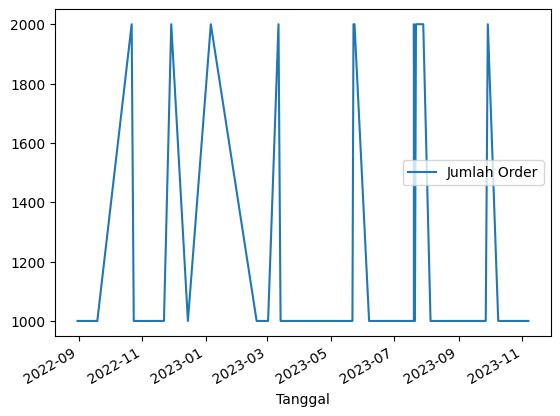

In [23]:
#Grafik Time Series
ivory_250 = daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory250", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
ivory_250['Jumlah Order'] = pd.to_numeric(ivory_250['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
ivory_250.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [24]:
daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory270", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
6,6,2022-08-08,Ivory270,1700,"1,000.00","1,700,000.00"
12,12,2022-08-10,Ivory270,2000,"1,000.00","2,000,000.00"
18,18,2022-08-12,Ivory270,2000,"1,000.00","2,000,000.00"
71,71,2022-09-08,Ivory270,5500,500.00,"2,750,000.00"
106,106,2022-09-24,Ivory270,950,"2,000.00","1,900,000.00"
131,131,2022-10-09,Ivory270,2300,"1,000.00","2,300,000.00"
133,133,2022-10-11,Ivory270,2700,"1,000.00","2,700,000.00"
142,142,2022-10-19,Ivory270,2000,"1,000.00","2,000,000.00"
144,144,2022-10-19,Ivory270,3500,"1,000.00","3,500,000.00"
154,154,2022-10-24,Ivory270,2700,"1,000.00","2,700,000.00"


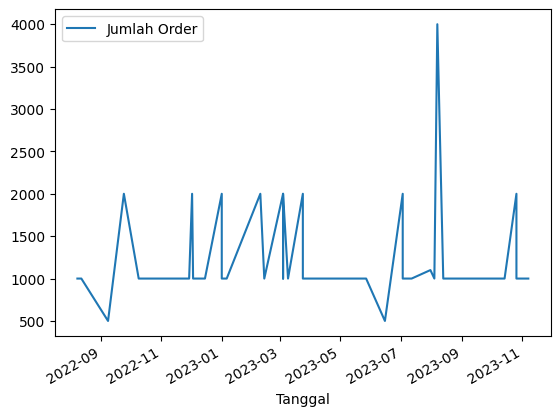

In [25]:
#Grafik Time Series
ivory_270 = daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory270", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
ivory_270['Jumlah Order'] = pd.to_numeric(ivory_270['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
ivory_270.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [26]:
daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory300", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
49,49,2022-08-30,Ivory300,1700,"1,000.00","1,700,000.00"
73,73,2022-09-08,Ivory300,2500,"1,000.00","2,500,000.00"
75,75,2022-09-08,Ivory300,1500,"2,000.00","3,000,000.00"
168,168,2022-10-24,Ivory300,1500,"2,000.00","3,000,000.00"
210,210,2022-11-22,Ivory300,2400,"1,000.00","2,400,000.00"
229,229,2022-11-29,Ivory300,1500,"1,000.00","1,500,000.00"
260,260,2022-12-12,Ivory300,4300,"1,000.00","4,300,000.00"
261,261,2022-12-12,Ivory300,2400,"1,000.00","2,400,000.00"
273,273,2022-12-14,KertasSisaIvory300,800,"1,000.00","800,000.00"
297,297,2022-12-15,Ivory300,1500,"2,000.00","3,000,000.00"


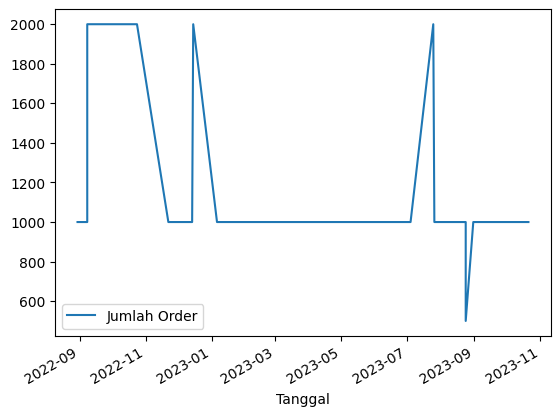

In [27]:
#Grafik Time Series
ivory_300 = daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory300", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
ivory_300['Jumlah Order'] = pd.to_numeric(ivory_300['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
ivory_300.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [28]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory350", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
277,277,2022-12-15,Ivory350,3500,"1,000.00","3,500,000.00"
472,472,2023-03-15,Ivory350,1100,"1,000.00","1,100,000.00"
473,473,2023-03-15,Ivory350,1100,"1,000.00","1,100,000.00"
516,516,2023-04-12,Ivory350,950,"2,000.00","1,900,000.00"
517,517,2023-04-13,Ivory350,950,"2,000.00","1,900,000.00"
582,582,2023-05-10,Ivory350,950,"10,000.00","9,500,000.00"
593,593,2023-05-17,Ivory350,2700,"1,000.00","2,700,000.00"
603,603,2023-05-22,Ivory350,900,"6,000.00","5,400,000.00"
604,604,2023-05-22,Ivory350,900,"4,000.00","3,600,000.00"
609,609,2023-05-25,Ivory350,900,"10,000.00","9,000,000.00"


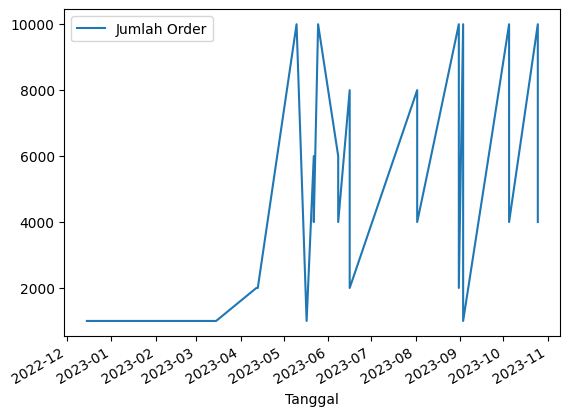

In [29]:
#Grafik Time Series
ivory_350 = daily_sales[(daily_sales['Jenis Produk'].str.contains("ivory350", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
ivory_350['Jumlah Order'] = pd.to_numeric(ivory_350['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
ivory_350.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [30]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[(daily_sales['Jenis Produk'].str.contains("craftfoodpak290", case=False, regex=False)) | (daily_sales['Jenis Produk'].str.contains("craft 290", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
25,25,2022-08-15,CraftFoodpak290,2200,"1,000.00","2,200,000.00"
27,27,2022-08-15,CraftFoodpak290,875,"3,000.00","2,625,000.00"
34,34,2022-08-18,CraftFoodpak290,975,"1,000.00","975,000.00"
39,39,2022-08-22,CraftFoodpak290,1300,"3,500.00","4,550,000.00"
42,42,2022-08-22,CraftFoodpak290,1200,"2,000.00","2,400,000.00"
43,43,2022-08-22,CraftFoodpak290,1850,"2,000.00","3,700,000.00"
111,111,2022-09-24,CraftFoodpak290,875,"3,000.00","2,625,000.00"
127,127,2022-10-06,CraftFoodpak290,875,"1,500.00","1,312,500.00"
143,143,2022-10-19,CraftFoodpak290,1200,"1,000.00","1,200,000.00"
169,169,2022-10-24,CraftFoodpak290,975,"1,000.00","975,000.00"


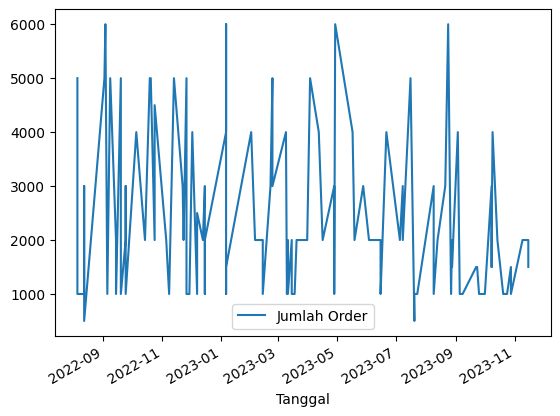

In [31]:
#Grafik Time Series
laminasi_290 = daily_sales[(daily_sales['Jenis Produk'].str.contains("craftlaminasi290", case=False, regex=False))| (daily_sales['Jenis Produk'].str.contains("craftlaminasi", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
laminasi_290['Jumlah Order'] = pd.to_numeric(laminasi_290['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
laminasi_290.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [32]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[(daily_sales['Jenis Produk'].str.contains("foodpak260", case=False, regex=False)) | (daily_sales['Jenis Produk'].str.contains("foodpakglossy260", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
0,0,2022-08-05,Foodpak260,1800,"1,000.00","1,800,000.00"
29,29,2022-08-15,Foodpak260Matte,2200,"1,000.00","2,200,000.00"
65,65,2022-09-05,Foodpak260Glossy,1200,"5,000.00","6,000,000.00"
80,80,2022-09-14,FoodpakGlossy260,1800,"1,000.00","1,800,000.00"
85,85,2022-09-14,Foodpak260Glossy,1600,"1,000.00","1,600,000.00"
91,91,2022-09-19,Foodpak260Glossy,1650,"1,000.00","1,650,000.00"
96,96,2022-09-19,Foodpak260Glossy,2300,"2,000.00","4,600,000.00"
121,121,2022-09-24,Foodpak260Glossy,1450,"5,000.00","7,250,000.00"
124,124,2022-10-04,FoodpakGlossy260,1800,"1,000.00","1,800,000.00"
183,183,2022-11-13,FoodpakGlossy260,1700,"1,000.00","1,700,000.00"


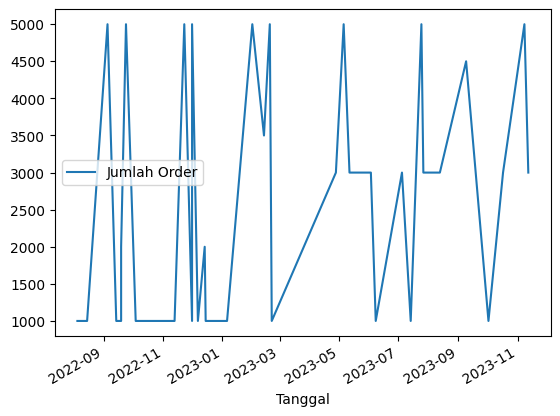

In [33]:
#Grafik Time Series
foodpak_260 = daily_sales[(daily_sales['Jenis Produk'].str.contains("foodpak260", case=False, regex=False)) | (daily_sales['Jenis Produk'].str.contains("foodpakglossy260", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
foodpak_260['Jumlah Order'] = pd.to_numeric(foodpak_260['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
foodpak_260.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [34]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[(daily_sales['Jenis Produk'].str.contains("foodpak245", case=False, regex=False))| (daily_sales['Jenis Produk'].str.contains("foodpakmatte245", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
1,1,2022-08-05,FoodpakMatte245,1900,"1,000.00","1,900,000.00"
37,37,2022-08-18,FoodpakMatte245,1800,"1,000.00","1,800,000.00"
92,92,2022-09-19,FoodpakMatte245,700,"2,500.00","1,750,000.00"
328,328,2023-01-06,Foodpak245Matte,1800,"1,000.00","1,800,000.00"
362,362,2023-01-06,FoodpakMatte245,1500,"1,000.00","1,500,000.00"
...,...,...,...,...,...,...
1031,1031,2023-10-31,FoodpakMatte245,1000,"2,000.00","2,000,000.00"
1035,1035,2023-11-03,FoodpakMatte245,1600,"1,000.00","1,600,000.00"
1036,1036,2023-11-03,FoodpakMatte245,1600,"1,000.00","1,600,000.00"
1039,1039,2023-11-03,FoodpakMatte245,1500,"1,000.00","1,500,000.00"


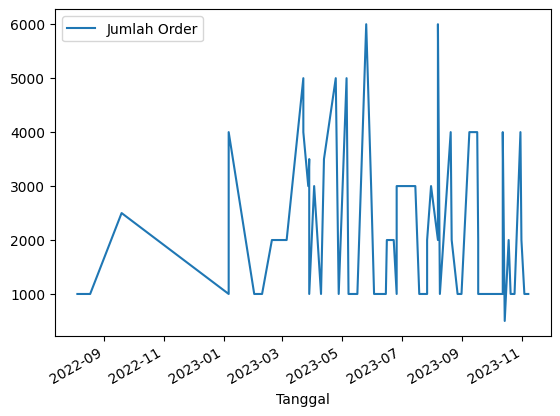

In [35]:
#Grafik Time Series
foodpak_245 = daily_sales[(daily_sales['Jenis Produk'].str.contains("foodpak245", case=False, regex=False))| (daily_sales['Jenis Produk'].str.contains("foodpakmatte245", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
foodpak_245['Jumlah Order'] = pd.to_numeric(foodpak_245['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
foodpak_245.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

In [36]:
# Menggunakan metode str.contains, case=False, dan regex=False
daily_sales[(daily_sales['Jenis Produk'].str.contains("greaseproof", case=False, regex=False))| (daily_sales['Jenis Produk'].str.contains("greaseproof", case=False, regex=False))]

,No,Tanggal,Jenis Produk,Harga,Jumlah Order,Total
54,54,2022-08-31,GreaseProof,400,"1,000.00","400,000.00"
58,58,2022-09-02,GreaseProof,500,"1,000.00","500,000.00"
68,68,2022-09-07,GreaseProof,400,"1,000.00","400,000.00"
74,74,2022-09-08,GreaseProof,300,"1,000.00","300,000.00"
84,84,2022-09-14,GreaseProof,950,"1,000.00","950,000.00"
...,...,...,...,...,...,...
980,980,2023-10-13,GreaseProof32gram,400,"1,000.00","400,000.00"
1017,1017,2023-10-25,GreaseProof,300,"1,000.00","300,000.00"
1020,1020,2023-10-27,GreaseProof,300,"1,000.00","300,000.00"
1042,1042,2023-11-06,GreaseProof,250,"3,500.00","875,000.00"


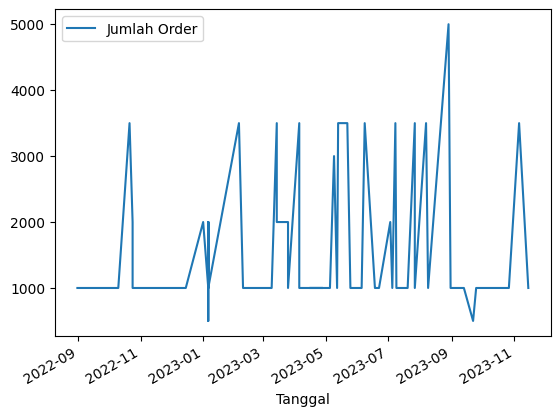

In [ ]:
#Grafik Time Series
greaseproof = daily_sales[(daily_sales['Jenis Produk'].str.contains("greaseproof", case=False, regex=False))| (daily_sales['Jenis Produk'].str.contains("greaseproof", case=False, regex=False))]

# Ubah tipe data kolom Jumlah Order menjadi numerik
greaseproof['Jumlah Order'] = pd.to_numeric(greaseproof['Jumlah Order'], errors='coerce')

# Buat plot garis untuk kolom Jumlah Order
greaseproof.plot(x='Tanggal', y='Jumlah Order', kind='line')
plt.show()

Menggunakan Algoritma Backpropagation untuk melatih sebuah model jaringan saraf tiruan berbasis Long Short-Term Memory(LSTM)¶
Setelah menyusun data historis penjualan masing masing produk menggunakan Time series analysis, kita akan memprediksi penjualannya menggunakan algoritma backpropagation.

Kita menggunakan algoritma backpropagation untuk memprediksi penjualan produk berdasarkan data historis. Algoritma backpropagation adalah sebuah metode optimasi yang menggunakan gradien turun untuk memperbarui bobot jaringan agar mengurangi kesalahan antara output berupa prediksi yang diharapkan dan yang dihasilkan.

Model ini memiliki lebih dari satu lapisan (Multilayer Perceptron). Sama seperti model multilayer perceptron pada umumnya, model ini memiliki tiga layer : Input layer, Hidden layer, Output layer.

Input Layer : Input layer adalah layer pertama yang menerima data dari sumber eksternal. Layer ini bertugas untuk mengubah data menjadi format yang sesuai dengan model. Dalam kasus ini, data berupa jumlah pesanan produk cetakan dalam rentang waktu tertentu. Input layer memiliki node yang jumlahnya tergantung time step yang ditentukan dalam model. Setiap node menerima satu nilai jumlah pesanan dan mengirimkannya ke hidden layer.
Penjelasan bagian input layer :

Karena kita menggunakan data historis dari time series analysis. Maka,data input yang digunakan adalah data jumlah order.Alasannya karena kita ingin memprediksi jumlah order produk berdasarkan data historis,bukan berdasarkan faktor faktor yang kurang relevan seperti jenis produk(karena tiap produk,transaksinya sudah dibagi),harga(harga kondisional),total(tergantung jumlah order dan harga yang dimana nilai harga kondisional).

Data input yang masuk ke dalam input layer adalah array 2D(yang berisi jumlah time step,jumlah fitur). Jika kalian melihat di dalam kodingan di bawah,ada variabel window_size yang nilainya itu kita gunakan untuk time step. Lalu,fungsi dari time step ini apa?. Saya akan jelaskan satu persatu.

Kenapa Menggunakan Array 2D ?

Array 2D adalah struktur data dengan dua dimensi, seperti tabel atau matriks. Dalam konteks data time series jumlah pesanan produk cetakan, kita menggunakan array 2D untuk menyimpan informasi tanggal dan jumlah pesanan.

Dalam implementasi ini, array 2D memiliki dua dimensi: baris dan kolom. Setiap baris mewakili satu entitas waktu atau satu observasi, sementara setiap kolom mewakili atribut atau fitur dari data tersebut. Misalnya, kita memiliki kolom untuk tanggal dan kolom untuk jumlah pesanan.

Create Dataset

Fungsi create_dataset yang telah dibuat bertujuan untuk mengubah data time series (seri waktu) menjadi array 2D dengan bentuk yang sesuai untuk model MLP (Multilayer Perceptron) dengan backpropagation. Fungsi ini menerima data dan window_size sebagai parameter, dan mengembalikan dua array 2D, yaitu X dan y.

Berikut gambaranya :image.png

Jika window_size adalah 10, maka fungsi create_dataset akan menghasilkan array 2D sebagai berikut:

X = [[50, 60, 70, 80, 90, 100, 110, 120, 130, 140]] y = [[150]]

Di sini, X adalah array 2D yang berisi 10 nilai jumlah pesanan dari tanggal 1 Maret 2023 sampai 10 Maret 2023, yang digunakan sebagai input untuk memprediksi jumlah pesanan pada tanggal 11 Maret 2023. Sedangkan y adalah array 2D yang berisi satu nilai jumlah pesanan pada tanggal 11 Maret 2023, yang merupakan output yang diharapkan dari prediksi.

Pembagian Data Latih dan Data Uji

Data latih dan data uji adalah dua bagian dari data yang digunakan untuk melatih dan mengevaluasi model. Data latih adalah bagian dari data yang digunakan untuk melatih dan mengembangkan model. Data uji adalah bagian dari data yang digunakan untuk mengevaluasi performa model yang sudah dilatih sebelumnya ketika menghadapi data baru yang belum pernah dilihat sebelumnya. Hal ini bertujuan untuk mengukur sejauh mana model mampu melakukan generalisasi.

Untuk membagi data latih dan data uji dengan rasio 80:20, kita dapat menggunakan fungsi train_test_split dari library sklearn.model_selection. Fungsi ini akan membagi data menjadi dua bagian, yaitu data latih dan data uji, sesuai dengan rasio yang ditentukan. Data latih harus memiliki rasio lebih besar dari data uji, seperti 80:20, 90:10, 70:30, dll.

Dari tabel data yang kita miliki, kita hanya perlu menggunakan kolom "Jumlah Order" sebagai input untuk model kita, karena kita ingin memprediksi jumlah pesanan produk cetakan berdasarkan data historis. Kolom lain seperti "Jenis Produk", "Harga", dan "Total" dianggap tidak relevan untuk prediksi tersebut.

Ketika kita melakukan proses pemisahan data latih dan data uji dengan rasio 80:20, kita pertama-tama akan melakukan pengolahan data dengan mengambil kolom "Jumlah Order". Setelah itu, kita akan menggunakan fungsi create_dataset untuk membuat data input dan output yang sesuai dengan model MLP (Multilayer Perceptron) dengan backpropagation.

Misalnya, jika data awal kita terdiri dari 100 entitas waktu, setelah proses pemisahan data dan pengolahan menggunakan create_dataset dengan window_size 10, kita akan mendapatkan 90 pasang data input dan output. Selanjutnya, kita dapat menggunakan fungsi train_test_split untuk membagi data tersebut menjadi data latih dan data uji sesuai dengan rasio yang diinginkan.

Dengan demikian, jika kita menggunakan rasio 80:20, data latih akan terdiri dari 72 pasang data input dan output, sedangkan data uji akan terdiri dari 18 pasang data input dan output. Data latih ini kemudian akan digunakan untuk melatih model MLP, sedangkan data uji akan digunakan untuk mengevaluasi kinerja model tersebut menggunakan metrik seperti MSE, MAE, dan MAPE.

Berikut gambaranya :image.png

Data latih: X[0] sampai X[71], y[0] sampai y[71]

Data uji: X[72] sampai X[89], y[72] sampai y[89]

Hidden Layer : 1 layer dengan 32 node dan fungsi aktivasi ReLU. Layer ini menerima input dari node input dan menghasilkan output berupa vektor 32 dimensi yang digunakan untuk memodelkan pola-pola kompleks dalam data input.
Penjelasan Bagian Hidden Layer

Layer Dense adalah bagian dari jaringan saraf tiruan yang terdiri dari beberapa node atau neuron. Setiap node pada layer Dense terhubung dengan setiap node pada layer sebelumnya, membentuk jaringan penuh. Pada model ini, layer Dense digunakan sebagai hidden layer untuk memproses informasi dari input sebelumnya.

Hidden Layer ini memiliki 32 node, yang artinya setiap node akan menghasilkan output berdasarkan kombinasi linear dari input yang diterimanya. Fungsi aktivasi yang digunakan pada setiap node adalah ReLU (Rectified Linear Unit), yang menghasilkan output x jika x positif, dan 0 jika x negatif.

Layer Dense menerima input dari node-node pada layer sebelumnya, dan setiap node di layer ini melakukan komputasi dengan menggunakan bobot (weights) yang telah diatur selama proses pelatihan model. Proses ini memungkinkan model untuk mempelajari pola-pola kompleks dalam data input.

Selanjutnya, output dari Hidden Layer ini, berupa vektor 32 dimensi, akan menjadi input untuk layer output. Layer output pada model ini adalah layer Dense dengan 1 node dan fungsi aktivasi linear. Fungsi aktivasi linear digunakan karena kita ingin melakukan regresi untuk memprediksi jumlah order, dan fungsi ini memberikan output yang sesuai dengan nilai inputnya tanpa mengalami transformasi.

Optimizer yang digunakan pada model ini adalah Adam, yang merupakan algoritma optimasi adaptif yang efisien dalam menyesuaikan laju pembelajaran selama pelatihan. Callback digunakan untuk menyimpan model terbaik berdasarkan nilai val_loss (fungsi kesalahan pada data validasi) dan menghentikan pelatihan jika tidak ada perbaikan setelah 10 epoch.

Fungsi Aktivasi Linear

Fungsi aktivasi ReLU (Rectified Linear Unit) adalah fungsi matematika yang menghasilkan nilai x jika x positif, dan 0 jika x negatif.

image.png

Fungsi ini didefinisikan sebagai:

f(x)=max(0,x)

ReLU memiliki beberapa keunggulan, seperti:

Mengatasi masalah vanishing gradient, di mana gradien menjadi sangat kecil sehingga menyebabkan kesulitan dalam pembelajaran pada model yang lebih dalam.
Komputasi yang lebih efisien karena hanya melakukan operasi sederhana berupa max(0,x).
Memberikan model kapasitas untuk mempelajari representasi yang lebih kompleks dari data.
Output Layer : Output Layer pada model ini terdiri dari satu node dengan fungsi aktivasi linear. Node ini menerima input dari Hidden Layer, yang telah memproses informasi dari input data. Fungsi aktivasi linear digunakan pada Output Layer karena kita melakukan tugas regresi, yaitu memprediksi nilai numerik (jumlah order). Fungsi aktivasi linear memberikan output yang sesuai dengan nilai inputnya tanpa mengalami transformasi.
Node ini menghasilkan output berupa nilai prediksi jumlah order. Selama proses pelatihan, model memperbarui bobot (weights) pada setiap node untuk mengurangi selisih antara nilai prediksi dan nilai aktual (ground truth). Proses ini dilakukan dengan mengoptimalkan fungsi kesalahan Mean Squared Error (MSE), yang mengukur rata-rata kuadrat perbedaan antara nilai prediksi dan nilai aktual.

Setelah model dilatih, evaluasi dilakukan menggunakan data uji untuk mengukur kinerja model pada data yang belum pernah dilihat sebelumnya. Metrik evaluasi yang digunakan meliputi MSE (Mean Squared Error), MAE (Mean Absolute Error), dan MAPE (Mean Absolute Percentage Error).

Perbedaan Pembagian Data Uji dan Data Latih untuk tiap produk, Perbedaan nilai window_size

Terkadang jika kita tidak memiliki data yang cukup akan ada kesalahan dalam melatih model kita. Contohnya seperti dibawah.

image.png

Masalah ini disebabkan karena Anda mencoba mengakses indeks yang tidak ada dalam tuple. Tuple adalah sebuah tipe data yang berisi sekumpulan nilai yang tidak dapat diubah. Setiap nilai dalam tuple memiliki indeks yang dimulai dari 01. Jika Anda mencoba mengakses indeks yang lebih besar dari jumlah nilai dalam tuple, Anda akan mendapatkan IndexError: tuple index out of range.

Dalam kode, kita mencoba mengubah bentuk array X menjadi array 2D dengan menggunakan fungsi np.reshape. Fungsi ini menerima sebuah tuple sebagai parameter yang menentukan bentuk baru dari array. Anda memberikan tuple (X.shape[0], X.shape1, 1) sebagai parameter, yang berarti Anda ingin array X memiliki dimensi pertama sebesar X.shape[0], dimensi kedua sebesar X.shape1, dan dimensi ketiga sebesar 1.

Namun, masalahnya adalah array X tidak memiliki dimensi kedua, karena array X kosong. Hal ini terjadi karena data uji Anda tidak cukup untuk membuat data uji dengan window_size = 10. Misalnya,data uji kita hanya memiliki 6 baris, sedangkan Anda membutuhkan setidaknya 11 baris untuk membuat data uji dengan window_size 10. Oleh karena itu, fungsi create_dataset mengembalikan array X dan y yang kosong.

Ketika mencoba mengakses X.shape1, kita sebenarnya mencoba mengakses indeks ke-1 dari tuple X.shape, yang tidak ada. Tuple X.shape hanya memiliki satu elemen, yaitu 0, yang menunjukkan bahwa array X tidak memiliki elemen. Oleh karena itu, kita mendapatkan IndexError: tuple index out of range.

Untuk mengatasi masalah ini, kita perlu memastikan bahwa data uji Anda cukup untuk membuat data uji dengan ukuran jendela yang Anda inginkan. Anda bisa mengubah proporsi data latih dan data uji, atau mengubah nilai window_size, atau menambahkan data baru ke data uji.

In [1]:
# Impor library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense
from keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
import warnings
from daterange import DateRange
from datetime import datetime
warnings.filterwarnings('ignore')

# Grafik Time Series
dupleks_270 = daily_sales[daily_sales['Jenis Produk'].str.contains('dupleks270', case=False, regex=False)]
# Buat plot data penjualan untuk melihat visualisasi dari seri waktu
plt.figure(figsize=(10, 6))
plt.plot(dupleks_270['Tanggal'], dupleks_270['Jumlah Order'])
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Order')
plt.title('Data Penjualan Produk Cetakan')
plt.show()

# Bagi data menjadi data latih dan data uji (sekian% data latih, sekian% data uji)
train, test = train_test_split(dupleks_270, test_size=0.2, shuffle=False)

# Skala data menggunakan MinMaxScaler
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train[['Jumlah Order']])
test_scaled = scaler.transform(test[['Jumlah Order']])

# Simpan parameter penskalaan
scale_min = scaler.data_min_[0]
scale_max = scaler.data_max_[0]

# Ubah data menjadi array 2D
def create_dataset(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size, 0])
        y.append(data[i+window_size, 0])
    X = np.array(X)
    y = np.array(y)
    return X, y

# Tentukan ukuran jendela (jumlah langkah waktu)
window_size = 2

# Buat data latih dan data uji
X_train, y_train = create_dataset(train_scaled, window_size)
X_test, y_test = create_dataset(test_scaled, window_size)

# Pilih model jaringan saraf tiruan berbasis MLP (backpropagation)
model = Sequential()
model.add(Dense(window_size*2, activation='relu', input_dim=window_size))
model.add(Dense(1))
model.compile(loss='mse', optimizer='adam')

# Tentukan callback untuk menyimpan model terbaik dan menghentikan pelatihan jika tidak ada perbaikan
checkpoint = ModelCheckpoint('best_model.h5', monitor='val_loss', save_best_only=True, mode='min')
earlystop = EarlyStopping(monitor='val_loss', patience=10, mode='min')
callbacks = [checkpoint, earlystop]

# Latih model dengan data latih
model.fit(X_train, y_train, epochs=100, batch_size=16, validation_data=(X_test, y_test), callbacks=callbacks)

# Evaluasi model dengan data uji
model.evaluate(X_test, y_test)

# Buat prediksi dengan data uji
y_pred = model.predict(X_test)

# Kembalikan data prediksi ke skala asli
y_pred = y_pred * (scale_max - scale_min) + scale_min

# Buat plot data aktual dan data prediksi
plt.figure(figsize=(10, 6))
plt.plot(test['Tanggal'][window_size:], test['Jumlah Order'][window_size:], label='Actual')
plt.plot(test['Tanggal'][window_size:], y_pred, label='Predicted')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Order')
plt.title('Prediksi Penjualan Produk Cetakan dengan Algoritma Backpropagation')
plt.xticks(rotation=45)
plt.grid(rotation=45)
plt.tight_layout()
plt.axvline(y_test[0], color='r', linestyle='--', label='Start of Test Set')
plt.axvline(y_test[-1], color='g', linestyle='--', label='End of Test Set')
plt.legend()
plt.show()

# Hitung nilai MSE, MAE, dan MAPE
mse = mean_squared_error(test['Jumlah Order'][window_size:], y_pred)
mae = mean_absolute_error(test['Jumlah Order'][window_size:], y_pred)
mape = mean_absolute_percentage_error(test['Jumlah Order'][window_size:], y_pred)

# Cetak nilai MSE, MAE, dan MAPE
print('MSE: ', mse)
print('MAE: ', mae)
print('MAPE: ', mape)


# Impor fungsi tabulate
from tabulate import tabulate

# Buat data tabular dari nilai aktual dan prediksi
data = np.column_stack((test['Jumlah Order'][window_size:], y_pred))

# Buat list tanggal
tanggal = test['Tanggal'][window_size:].astype(str).tolist()

# Ubah tipe data array numpy menjadi string
data = data.astype(str)

# Tambahkan kolom tanggal ke data
data = np.insert(data, 0, tanggal, axis=1)



# Ubah header tabel
headers = ['Tanggal', 'Actual', 'Predicted']

# Buat tabel dengan header, format, dan kolom baru
table = tabulate(data, headers=headers, tablefmt='fancy_grid')

table = table.replace('  ', ' ')  # Menghapus spasi ganda untuk tampilan yang lebih baik
# ubah format angka dalam tabel
for i in range(1, data.shape[1]):
    table = table.replace(data[9:, i].astype(str), data[:, i].astype(str).str.replace('.', ',').tolist())


# Cetak tabel
print(table)

ModuleNotFoundError: No module named 'tensorflow'